# GARCH Model for Global Indices

## 1. Project Introduction

This project aims to estimate GARCH volatility
models for four major global equity indices:
the S&P 500, EURO STOXX 50, Nikkei 225,
and FTSE 100.

The main objective is to compare volatility
persistence across these markets using
GARCH(1,1) models.

## 2. Import Libraries

In this section, we import the Python libraries required for data collection, processing, visualisation, and GARCH modelling.

- **pandas and numpy:** Data manipulation and
  numerical calculations.
- **yfinance:** Downloading historical financial
  market data.
- **matplotlib and seaborn:** Visualising returns
  and volatility.
- **arch:** Estimating GARCH volatility models.
- **statsmodels and scipy:** Statistical analysis
  and model diagnostics.


In [443]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from arch import arch_model
from statsmodels.stats.diagnostic import het_arch
from scipy import stats

## 3. Load Data

Historical daily price data for four major global equity indices (S&P 500, EURO STOXX 50, Nikkei 225, and FTSE 100) are downloaded
from Yahoo Finance using the `yfinance` library.

The sample period covers January 2015 to December 2025. These datasets will be used to calculate daily logarithmic returns and compare volatility dynamics across markets.

In [444]:
tickers = {
    "S&P 500": "^GSPC",
    "EURO STOXX 50": "^STOXX50E",
    "Nikkei 225": "^N225",
    "FTSE 100": "^FTSE"
}

data = {}

for name, ticker in tickers.items():
    data[name] = yf.download(
        ticker,
        start="2015-01-01",
        end="2026-01-01",
        auto_adjust=True,
        progress=False
    )

d:\Learning_Materials\GARCH_project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
d:\Learning_Materials\GARCH_project\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
d:\Learning_Materials\GARCH_project\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
d:\Learning_Materials\GARCH_

## 4. Clean Data

Before calculating logarithmic returns and
estimating GARCH models, the historical price
data must be checked for consistency and
completeness.

The data cleaning process involves:

1. Checking the number of observations,
   missing values, and duplicate dates
   for each index.
2. Extracting daily closing prices from
   the downloaded datasets.
3. Combining the four indices into a
   single DataFrame, aligned by trading date.
4. Identifying missing observations caused
   by differences in market trading calendars.

Missing values may occur because different stock markets have different trading holidays. We keep these missing values instead of filling them with artificial prices.

Daily logarithmic returns will be calculated separately for each index using its own trading dates. The return series will then be aligned by date for comparison across markets.

In [445]:
# Check data quality for each index

for name, df in data.items():

    print(f"\n{name}")

    print("Observations:", len(df))

    print("Missing values:",
          df.isnull().sum().sum())

    print("Duplicate dates:",
          df.index.duplicated().sum())


prices = pd.concat(
    {
        name: df["Close"].squeeze()
        for name, df in data.items()
    },
    axis=1
)

prices = prices.sort_index()

print(prices.head())


S&P 500
Observations: 2766
Missing values: 0
Duplicate dates: 0

EURO STOXX 50
Observations: 2763
Missing values: 0
Duplicate dates: 0

Nikkei 225
Observations: 2688
Missing values: 0
Duplicate dates: 0

FTSE 100
Observations: 2778
Missing values: 0
Duplicate dates: 0
                S&P 500  EURO STOXX 50    Nikkei 225     FTSE 100
Date                                                             
2015-01-02  2058.199951            NaN           NaN  6547.799805
2015-01-05  2020.579956    3023.139893  17408.710938  6417.200195
2015-01-06  2002.609985            NaN  16883.189453  6366.500000
2015-01-07  2025.900024    3026.790039  16885.330078  6419.799805
2015-01-08  2062.139893    3135.080078  17167.099609  6570.000000


C:\Users\scarl\AppData\Local\Temp\ipykernel_10572\3125475563.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  prices = pd.concat(


## 5. Calculate Log Returns

Daily logarithmic returns are calculated from
the closing prices of each equity index using:

$$r_t = 100 \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Returns are multiplied by 100 to express
them in percentage terms for GARCH estimation.

Each index's returns are calculated using
its own trading calendar to avoid introducing
artificial returns from market holidays.



In [446]:
# Calculate daily log returns for each index

log_returns = pd.concat(
    {
        name: 100 * np.log(
            close / close.shift(1)
        )
        for name, df in data.items()
        for close in [df["Close"].squeeze().dropna()]
    },
    axis=1
)

# Sort returns by date
log_returns = log_returns.sort_index()

# Display the first five rows
display(log_returns.head())

C:\Users\scarl\AppData\Local\Temp\ipykernel_10572\1293164591.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  log_returns = pd.concat(


,S&P 500,EURO STOXX 50,Nikkei 225,FTSE 100
Date,,,,
2015-01-02,NaN,NaN,NaN,NaN
2015-01-05,-1.844721,NaN,NaN,-2.014717
2015-01-06,-0.893325,NaN,-3.065229,-0.793205
2015-01-07,1.156274,0.120667,0.012678,0.833707
2015-01-08,1.773017,3.515205,1.654954,2.312690


## 6. Exploratory Data Aanalysis
### Historical Price Plots

We visualise the historical daily closing
prices of the S&P 500, EURO STOXX 50,
Nikkei 225, and FTSE 100 to examine
long-term market trends and identify
periods of substantial price movements.

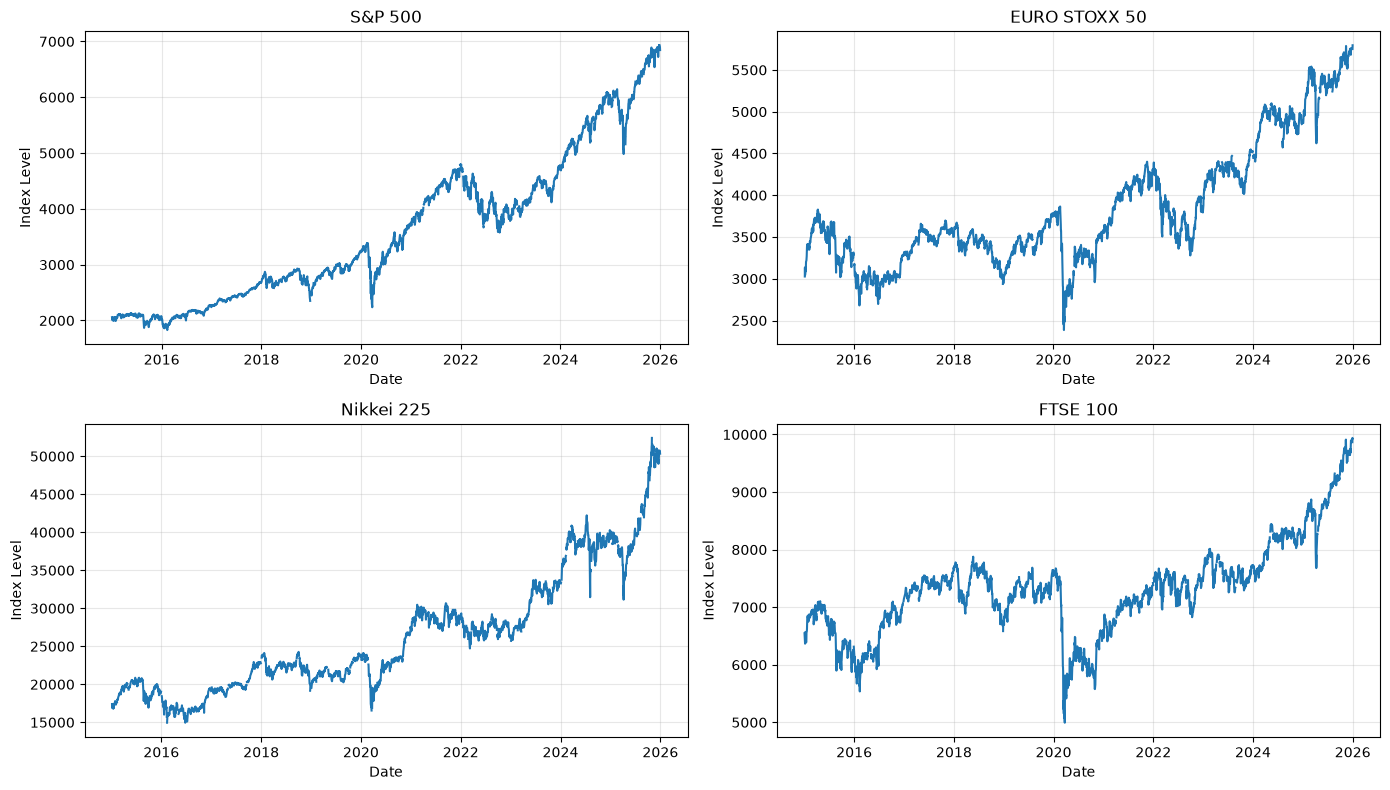

In [447]:
# Plot historical closing prices

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, name in zip(axes.flatten(), prices.columns):
    ax.plot(prices.index, prices[name])

    ax.set_title(name)
    ax.set_xlabel("Date")
    ax.set_ylabel("Index Level")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Daily Log Return Plots

We plot the daily logarithmic returns of
the four equity indices to examine their
fluctuations over time.

The plots help identify periods of unusually
large positive or negative returns and provide
preliminary visual evidence of volatility
clustering, where large return movements
tend to occur close together in time.

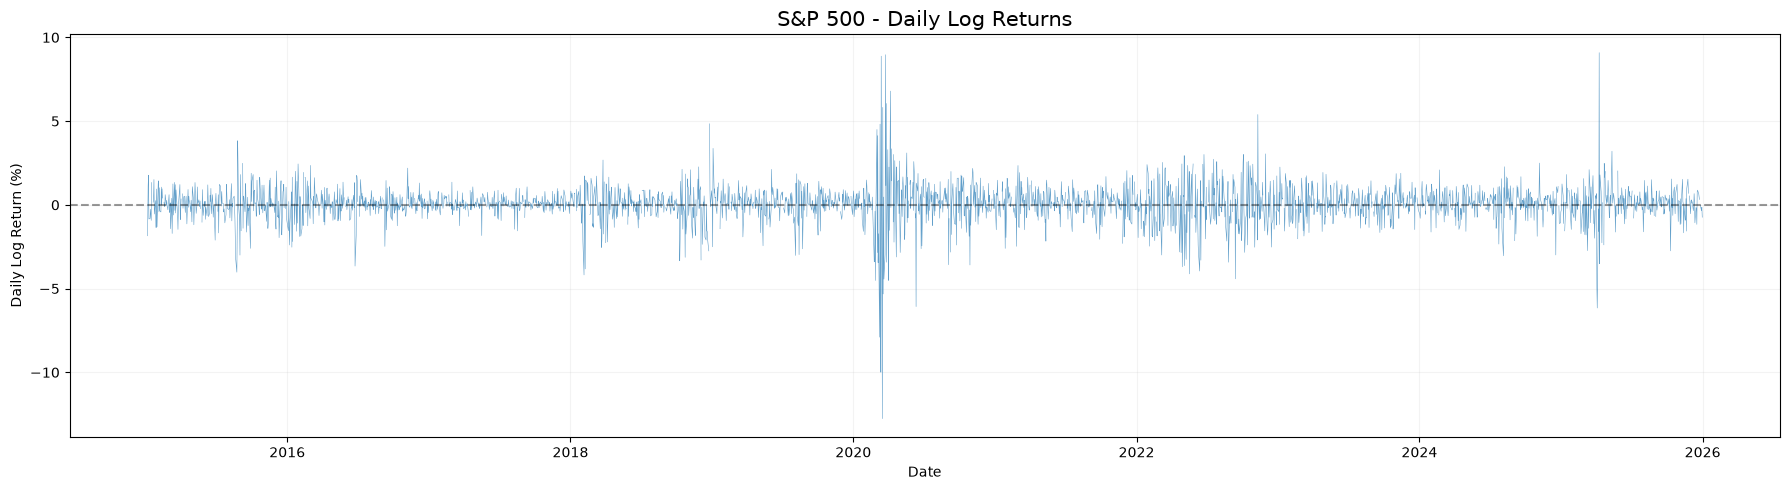

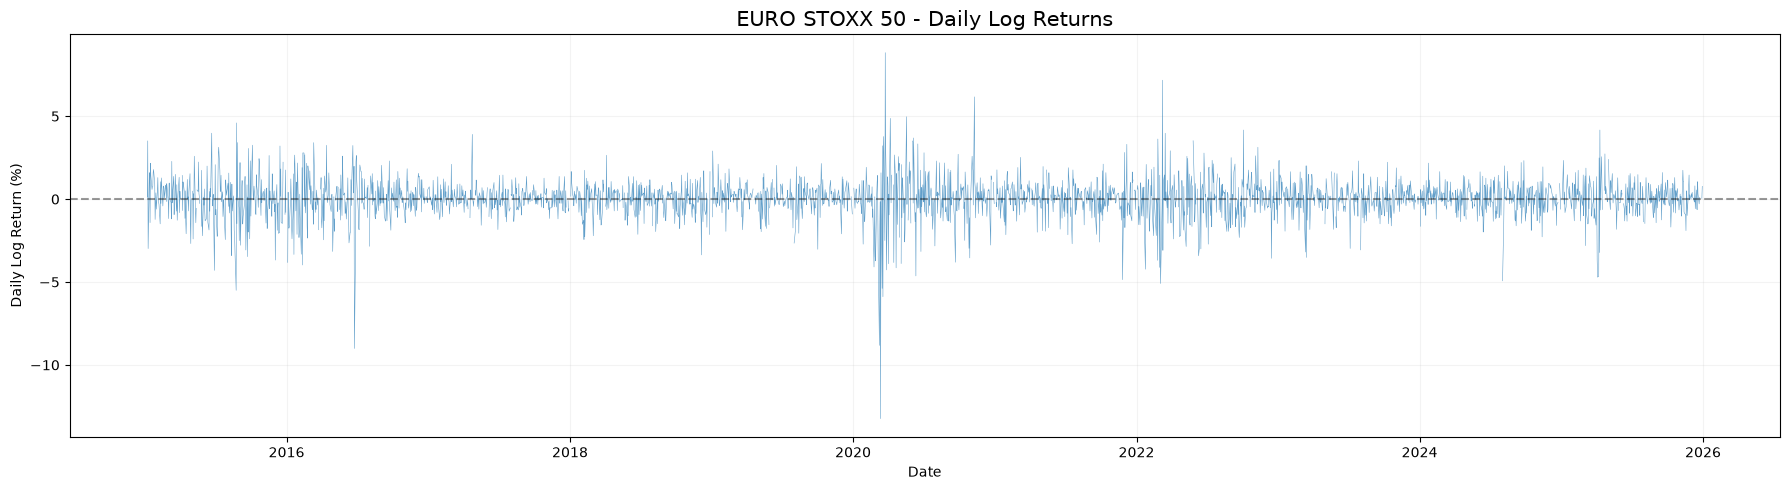

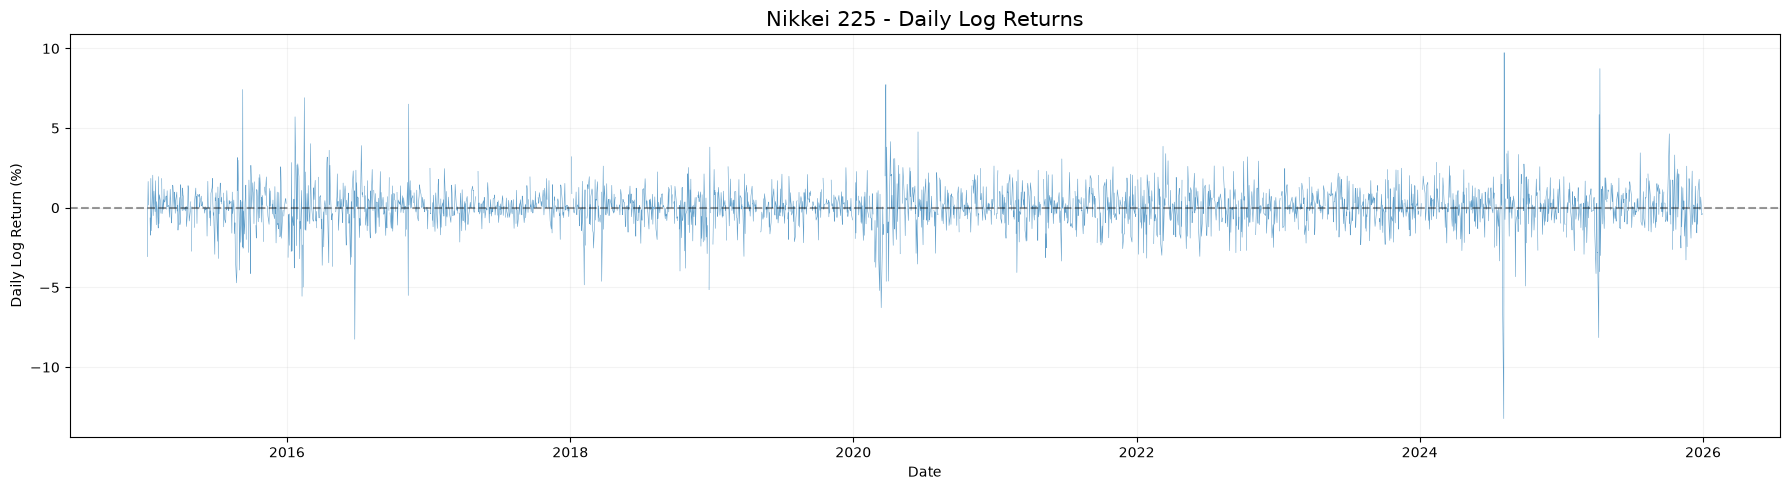

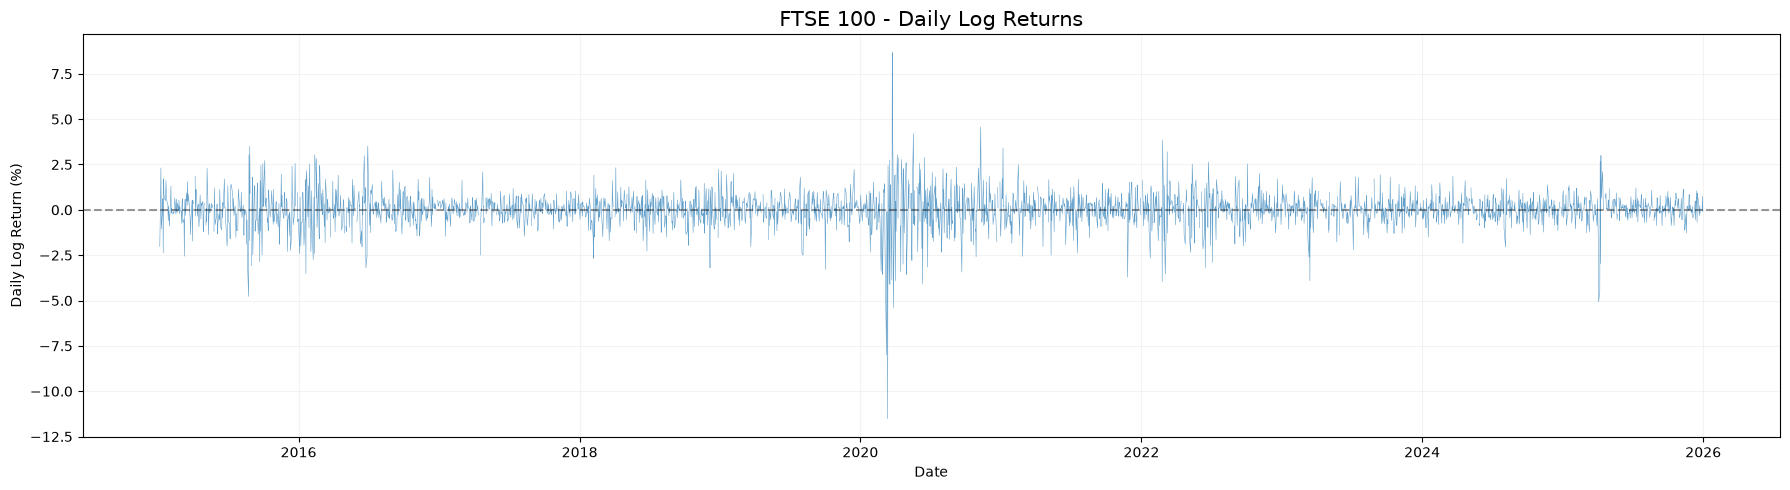

In [448]:
# Plot daily logarithmic returns

# Plot daily logarithmic returns vertically

# Plot daily logarithmic returns separately

for name in log_returns.columns:

    returns = log_returns[name]

    plt.figure(figsize=(18, 5))

    plt.plot(
        returns.index,
        returns,
        linewidth=0.4,
        alpha=0.7
    )

    plt.title(
        f"{name} - Daily Log Returns",
        fontsize=15
    )

    plt.xlabel("Date")
    plt.ylabel("Daily Log Return (%)")

    plt.axhline(
        0,
        color="black",
        linestyle="--",
        alpha=0.4
    )

    plt.grid(alpha=0.15)
    plt.tight_layout()
    plt.show()

### Rolling Volatility

We calculate the 30-day rolling standard
deviation of daily logarithmic returns
for each equity index to examine how market
volatility changes over time.

Rolling volatility helps identify periods
of market stability and turbulence,
providing preliminary evidence of
time-varying volatility and volatility
clustering.

In [449]:
rolling_vol = pd.DataFrame({
    name: log_returns[name].dropna().rolling(30).std()
    for name in log_returns.columns
})

display(rolling_vol.head())

,S&P 500,EURO STOXX 50,Nikkei 225,FTSE 100
Date,,,,
2015-01-05,NaN,NaN,NaN,NaN
2015-01-06,NaN,NaN,NaN,NaN
2015-01-07,NaN,NaN,NaN,NaN
2015-01-08,NaN,NaN,NaN,NaN
2015-01-09,NaN,NaN,NaN,NaN


The 30-day rolling volatility series are plotted
separately for each index to visualise changes
in market volatility over time.

Higher values indicate periods of greater
return fluctuations, while lower values
indicate relatively stable market conditions.

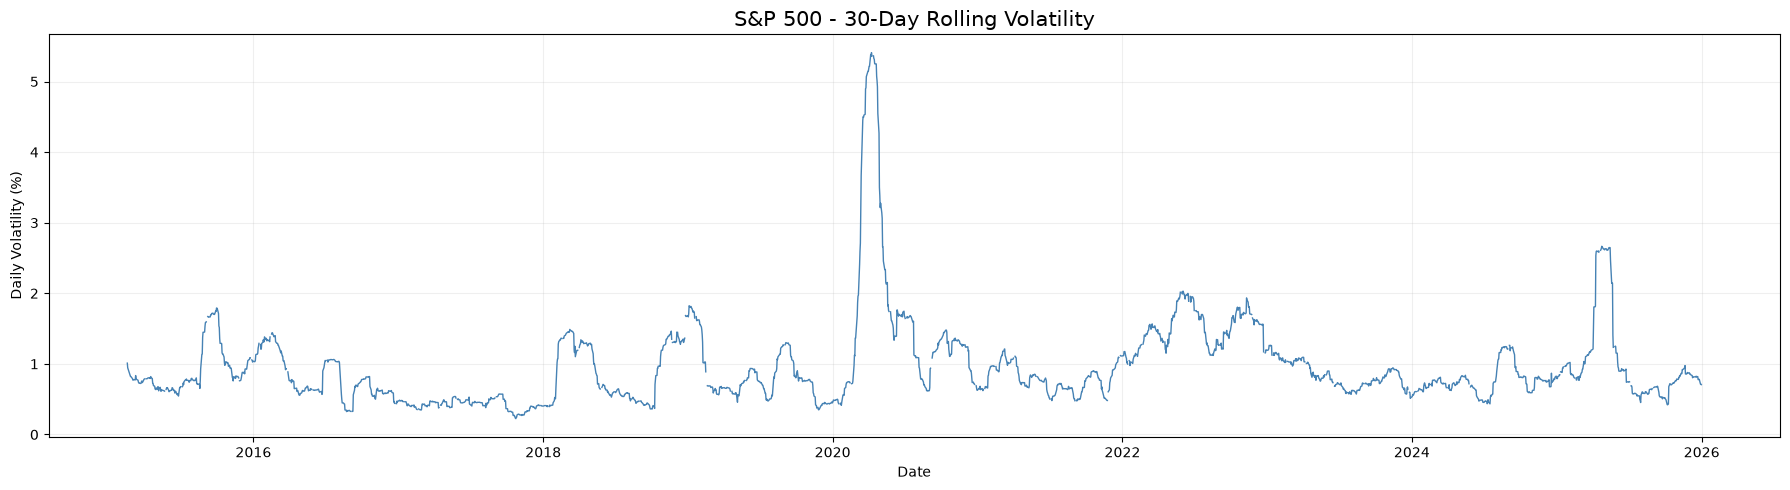

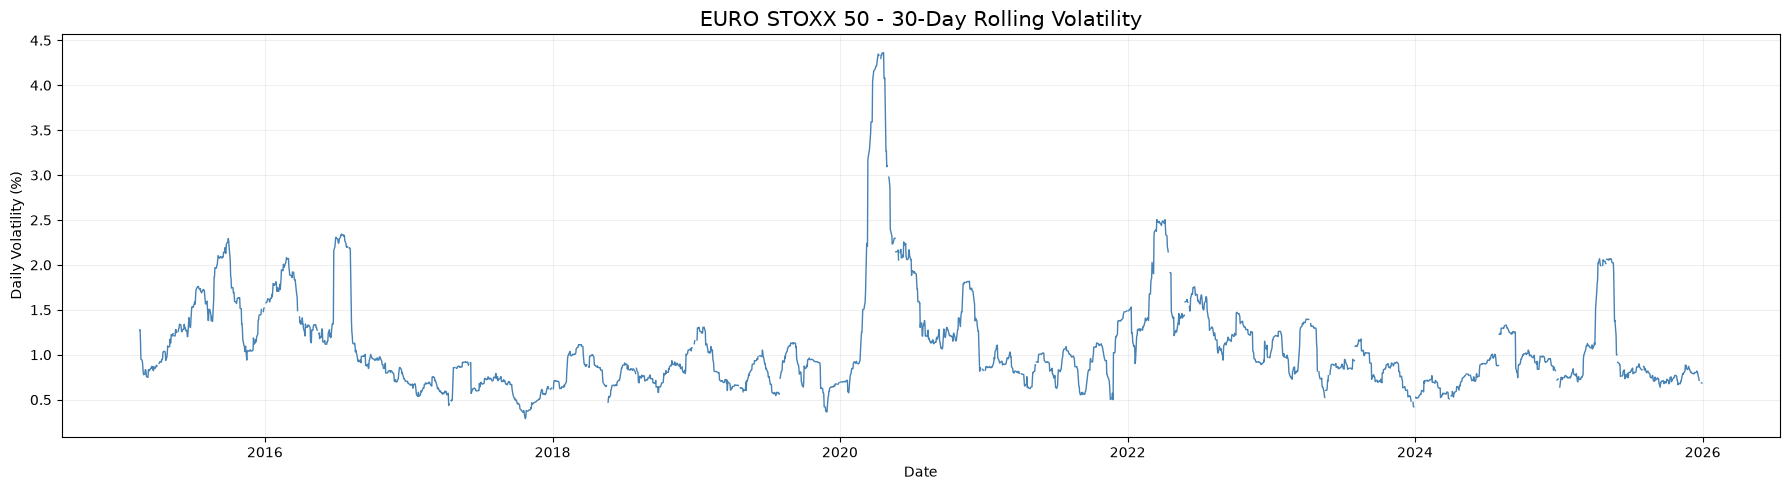

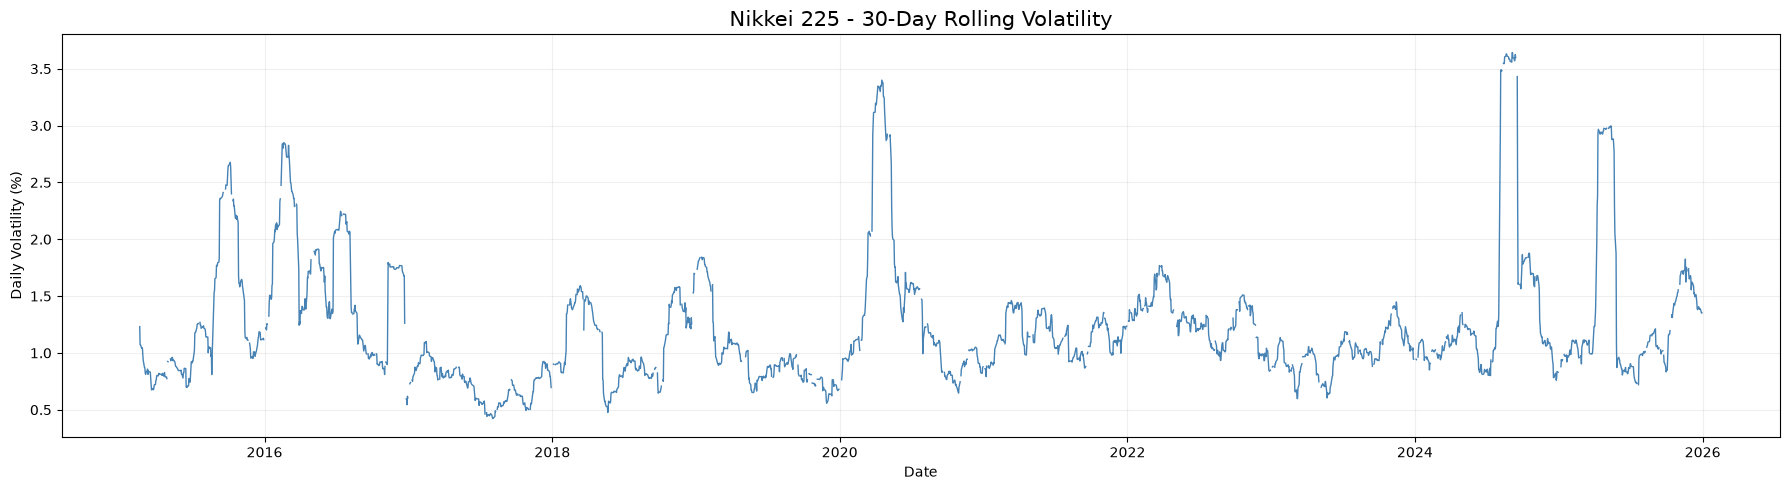

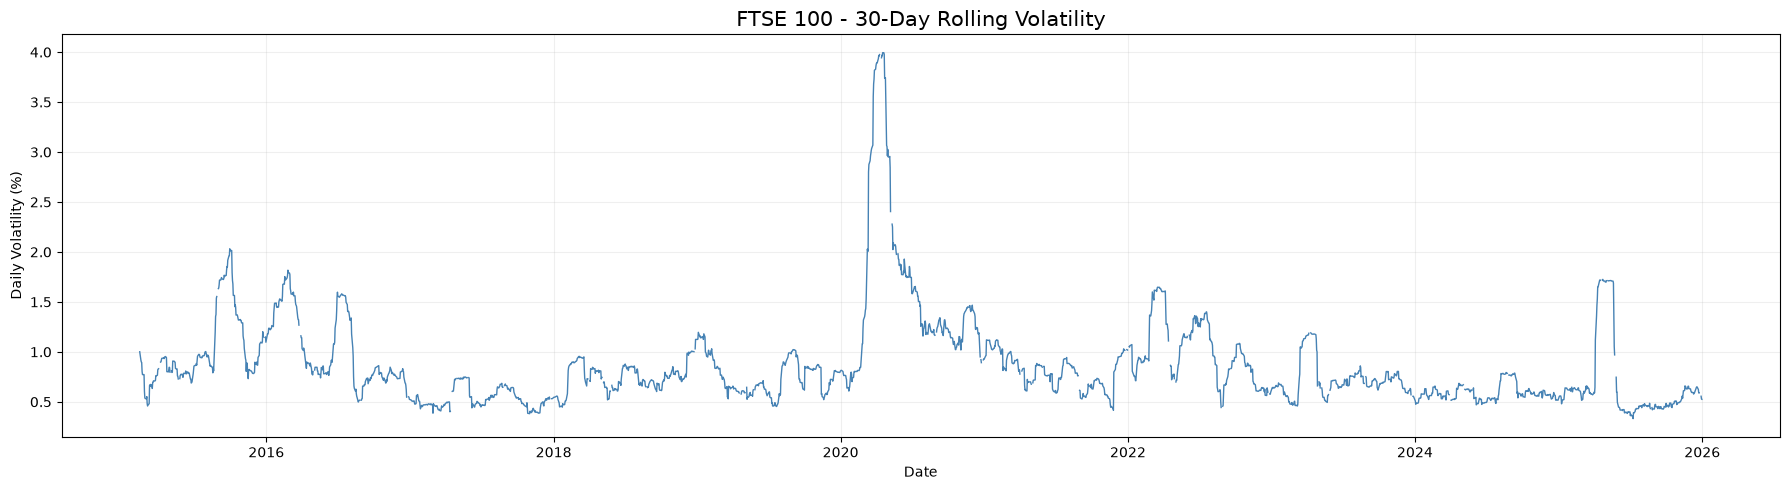

In [450]:
# Plot 30-day rolling volatility for each index

for name in rolling_vol.columns:

    vol = rolling_vol[name]

    plt.figure(figsize=(18, 5))

    plt.plot(
        vol.index,
        vol,
        linewidth=1,
        color="steelblue"
    )

    plt.title(
        f"{name} - 30-Day Rolling Volatility",
        fontsize=15
    )

    plt.xlabel("Date")
    plt.ylabel("Daily Volatility (%)")

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### Return Distributions

We examine the distributions of daily
logarithmic returns for the four equity
indices using histograms and kernel
density estimates (KDE).

The analysis helps us understand the shape
of return distributions, including their
concentration around the mean, asymmetry,
and potential extreme observations.

These characteristics are relevant to
GARCH modelling, particularly when considering
alternative assumptions about the distribution
of standardised innovations.

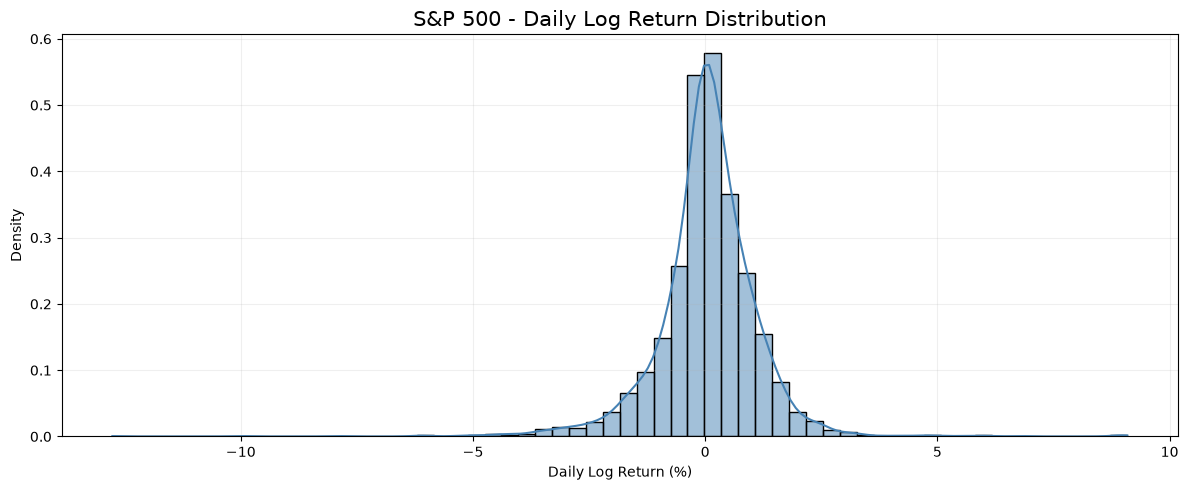

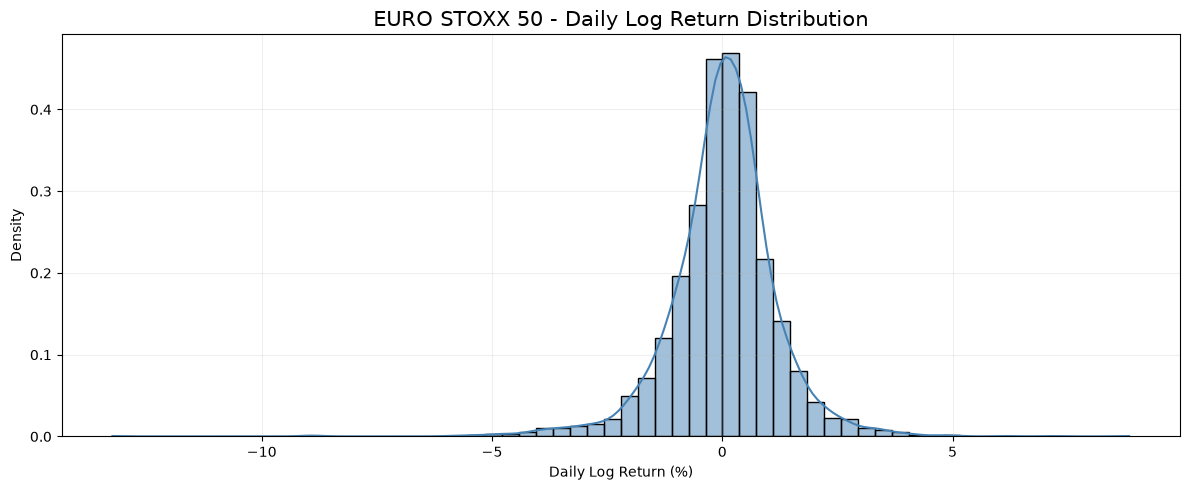

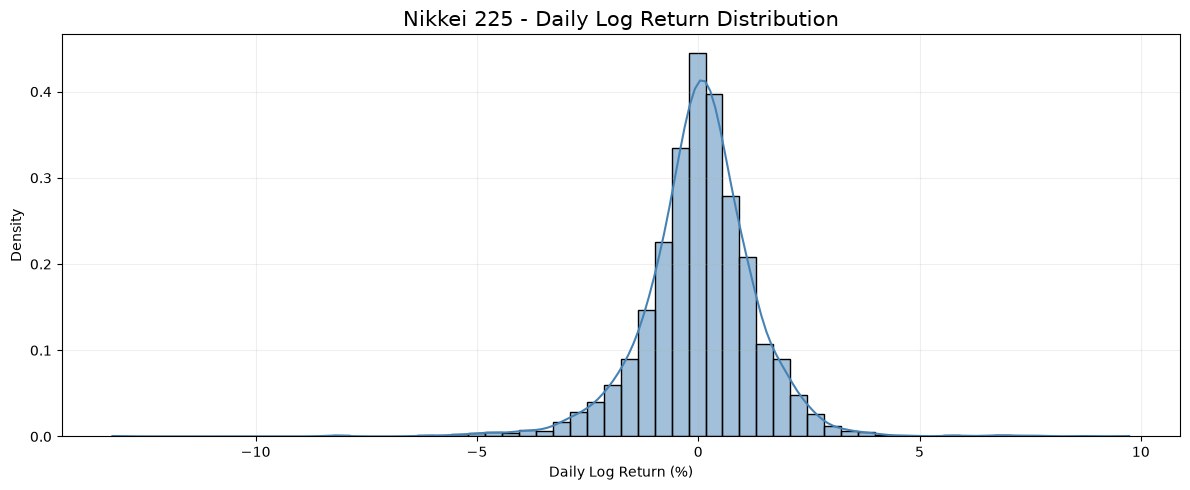

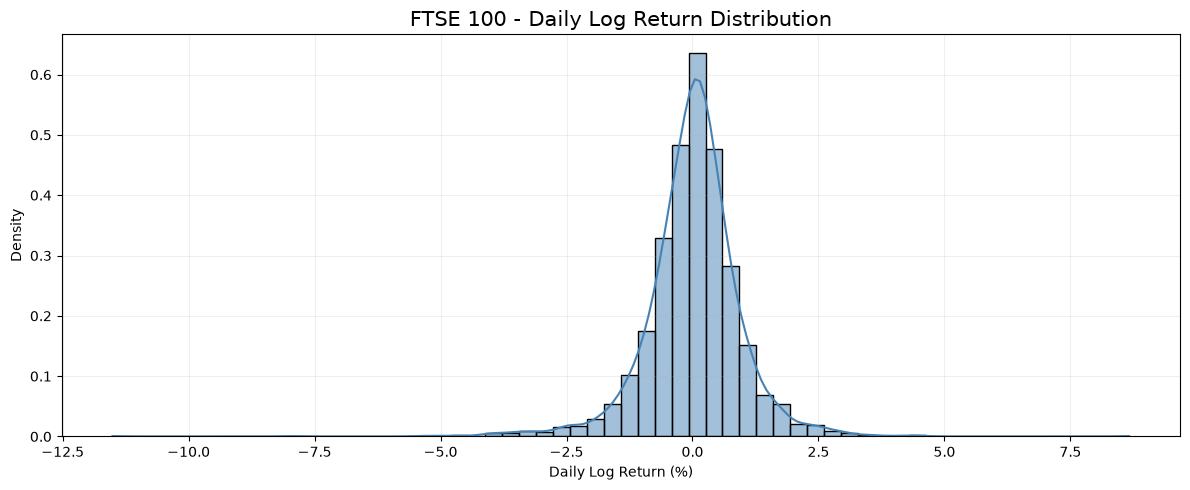

In [451]:
# Plot daily log return distributions

for name in log_returns.columns:

    returns = log_returns[name].dropna()

    plt.figure(figsize=(12, 5))

    sns.histplot(
        returns,
        bins=60,
        kde=True,
        stat="density",
        color="steelblue"
    )

    plt.title(
        f"{name} - Daily Log Return Distribution",
        fontsize=15
    )

    plt.xlabel("Daily Log Return (%)")
    plt.ylabel("Density")

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### EDA Summary

The exploratory analysis examines historical price movements, daily logarithmic returns, rolling volatility, and return distributions across the four equity indices.

The return plots are used to identify unusually large market movements and potential volatility clustering, while the 30-day rolling standard deviations illustrate how volatility changes over time.

The return distributions provide further insight into the shape of the data, including possible asymmetry and extreme observations.

These analyses motivate the use of GARCH models to estimate time-varying conditional volatility. The next stage is to fit a GARCH(1,1) model to each index and compare the estimated volatility dynamics.

## 7. Model Building

### GARCH(1,1) Model Specification

We estimate GARCH(1,1) models to capture
time-varying conditional volatility in daily
equity index returns.

The model consists of a constant mean equation
and a conditional variance equation:

$$r_t = \mu + \epsilon_t$$

$$\sigma_t^2 = \omega + \alpha\epsilon_{t-1}^2
+ \beta\sigma_{t-1}^2$$

The parameters are estimated using maximum
likelihood estimation (MLE). We begin with
the S&P 500 before applying the same
methodology to the remaining three indices.

### GARCH(1,1) Estimation: S&P 500

We begin by estimating a GARCH(1,1) model
for the S&P 500 using daily logarithmic
returns.

The model assumes a constant conditional
mean and normally distributed standardised
innovations. Model parameters are estimated
using maximum likelihood estimation (MLE)
with the Python `arch` library.

In [452]:
sp500_returns = log_returns["S&P 500"].dropna()

In [453]:
from arch import arch_model

model = arch_model(
    sp500_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

# Estimate GARCH parameters using MLE

result = model.fit(disp="off")

print(result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                S&P 500   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3572.12
Distribution:                  Normal   AIC:                           7152.24
Method:            Maximum Likelihood   BIC:                           7175.94
                                        No. Observations:                 2765
Date:                Wed, Oct 28 2026   Df Residuals:                     2764
Time:                        19:14:20   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0789  1.428e-02      5.521  3.378e-08 [5.086e-0

In [454]:
# Display estimated GARCH parameters

print(result.params)

mu          0.078859
omega       0.039453
alpha[1]    0.174750
beta[1]     0.793750
Name: params, dtype: float64


### Volatility Persistence: S&P 500

Volatility persistence is measured by the
sum of the ARCH and GARCH coefficients:

$$\text{Persistence} = \alpha + \beta$$

For a stationary GARCH(1,1) model, a value
closer to one indicates that the effects
of volatility shocks decay more slowly
over time.

In [455]:
# Extract estimated GARCH coefficients

alpha = result.params["alpha[1]"]
beta = result.params["beta[1]"]

# Calculate volatility persistence

persistence = alpha + beta

print(f"Alpha: {alpha:.4f}")
print(f"Beta: {beta:.4f}")
print(f"Volatility Persistence: {persistence:.4f}")

Alpha: 0.1748
Beta: 0.7938
Volatility Persistence: 0.9685


### GARCH(1,1) Estimation Across Global Equity Indices

We extend the GARCH(1,1) analysis to all
four equity indices using the same model
specification: a constant conditional mean,
GARCH(1,1) volatility, and normally
distributed standardised innovations.

Each model is estimated separately using
the index's available daily logarithmic
returns. The estimated parameters are then
collected to compare volatility dynamics
and persistence across markets.

In [456]:
# Fit GARCH(1,1) models for all four indices

garch_results = {}

for name in log_returns.columns:

    returns = log_returns[name].dropna()

    model = arch_model(
        returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal"
    )

    garch_results[name] = model.fit(disp="off")

    print(f"{name}: Model fitted successfully")

S&P 500: Model fitted successfully
EURO STOXX 50: Model fitted successfully
Nikkei 225: Model fitted successfully
FTSE 100: Model fitted successfully


### GARCH Parameter Comparison

The estimated mean and volatility parameters
are extracted from each GARCH(1,1) model.

Volatility persistence is measured by the
sum of the ARCH and GARCH coefficients:

$$\text{Persistence} = \alpha + \beta$$

For a stationary GARCH(1,1) model, a
persistence value closer to one indicates
slower decay of volatility shocks.

The estimated coefficients are compared
across the four equity markets.

In [457]:
# Extract estimated parameters

parameter_table = []

for name, result in garch_results.items():

    params = result.params

    mu = params["mu"]
    omega = params["omega"]
    alpha = params["alpha[1]"]
    beta = params["beta[1]"]

    persistence = alpha + beta

    parameter_table.append({
        "Index": name,
        "Mu": mu,
        "Omega": omega,
        "Alpha": alpha,
        "Beta": beta,
        "Persistence": persistence,
        "Convergence Flag": result.convergence_flag
    })

# Convert results into a DataFrame
parameter_table = pd.DataFrame(parameter_table)

# Display the comparison table
display(parameter_table.round(4))

,Index,Mu,Omega,Alpha,Beta,Persistence,Convergence Flag
0,S&P 500,0.0789,0.0395,0.1748,0.7938,0.9685,0
1,EURO STOXX 50,0.0628,0.0625,0.1540,0.8046,0.9586,0
2,Nikkei 225,0.0737,0.1198,0.1562,0.7733,0.9294,0
3,FTSE 100,0.0372,0.0599,0.1706,0.7589,0.9296,0


### Volatility Persistence Comparison

Volatility persistence is compared across
the four equity indices using the sum of
the estimated ARCH and GARCH coefficients:

$$\text{Persistence} = \alpha + \beta$$

For a stationary GARCH(1,1) model, a
persistence value closer to one indicates
that volatility shocks tend to decay
more slowly over time.

We visualise the estimated persistence
coefficients to identify differences in
volatility dynamics across global
equity markets.

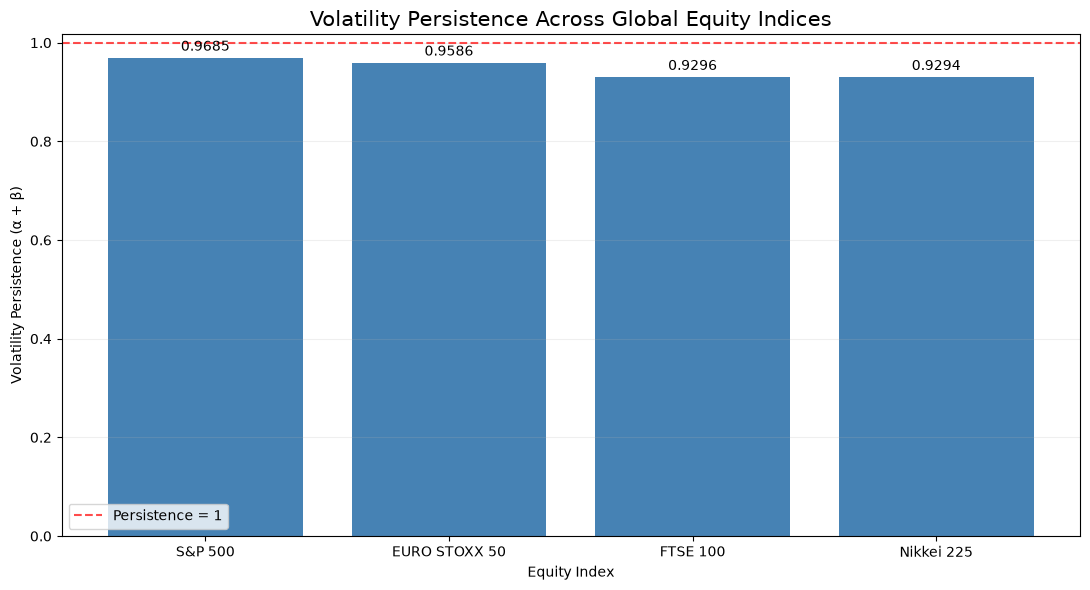

In [458]:
# Plot volatility persistence comparison

persistence_data = parameter_table.sort_values(
    by="Persistence",
    ascending=False
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    persistence_data["Index"],
    persistence_data["Persistence"],
    color="steelblue"
)

plt.title(
    "Volatility Persistence Across Global Equity Indices",
    fontsize=15
)

plt.xlabel("Equity Index")
plt.ylabel("Volatility Persistence (α + β)")

plt.axhline(
    y=1,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Persistence = 1"
)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretation of Volatility Persistence

The estimated GARCH(1,1) persistence
coefficients vary across the four equity
indices.

S&P 500 exhibits
the highest estimated persistence of 0.9685,
suggesting that volatility shocks tend to
have a more prolonged effect in this market
under the fitted model.

In contrast, Nikkei 225
has the lowest estimated persistence of
0.9294, indicating relatively faster decay
of volatility shocks.

These results describe differences in
estimated volatility dynamics rather than
differences in average volatility levels.

Further statistical analysis would be
required to assess whether the observed
differences are significant.

## 8. Model Evaluation

### Residual Diagnostics

Residual diagnostics are conducted to examine
the unexplained movements in daily returns
after estimating the GARCH(1,1) models.

For the constant mean model, residuals
are defined as:

$$\hat{\epsilon}_t = r_t - \hat{\mu}$$

We first visualise the residual series for
each equity index to identify unusually
large shocks and examine their behaviour
over time.

Standardised residuals and formal diagnostic
tests will be considered in the following steps.

In [459]:
# Extract residuals from the fitted GARCH models

garch_residuals = {}

for name, result in garch_results.items():

    garch_residuals[name] = result.resid.dropna()

    print(
        f"{name}: {len(garch_residuals[name])} residuals"
    )

S&P 500: 2765 residuals
EURO STOXX 50: 2762 residuals
Nikkei 225: 2687 residuals
FTSE 100: 2777 residuals


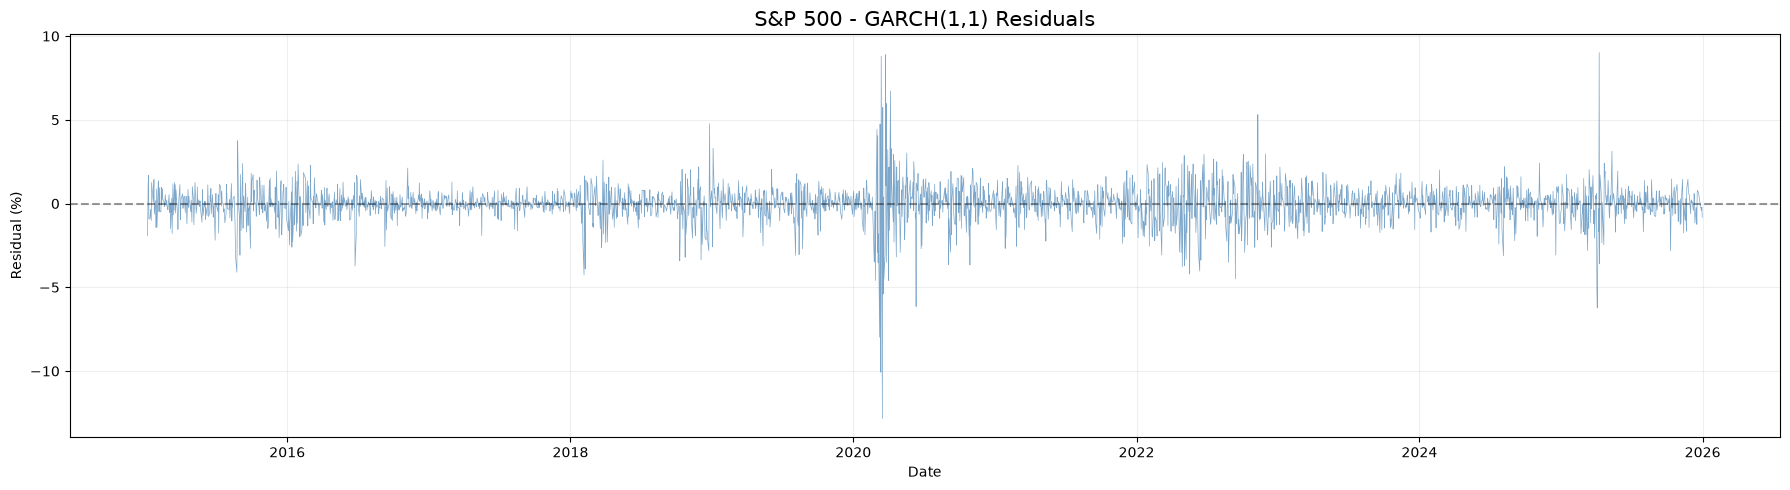

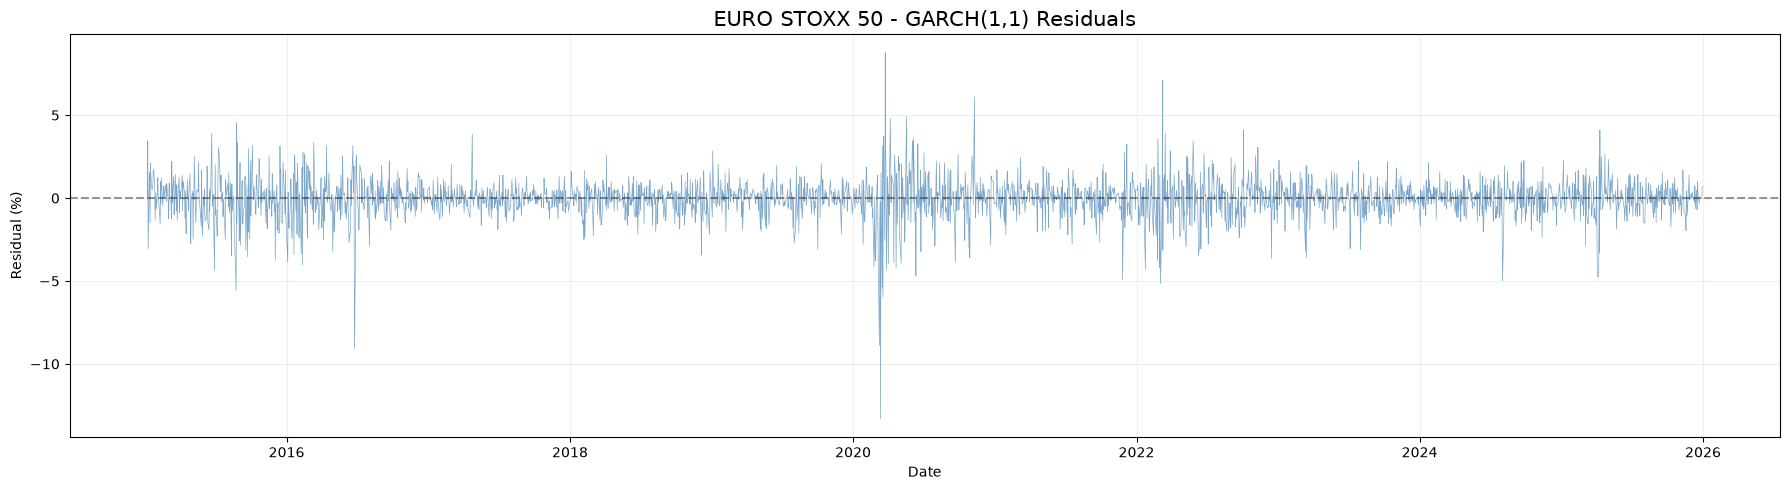

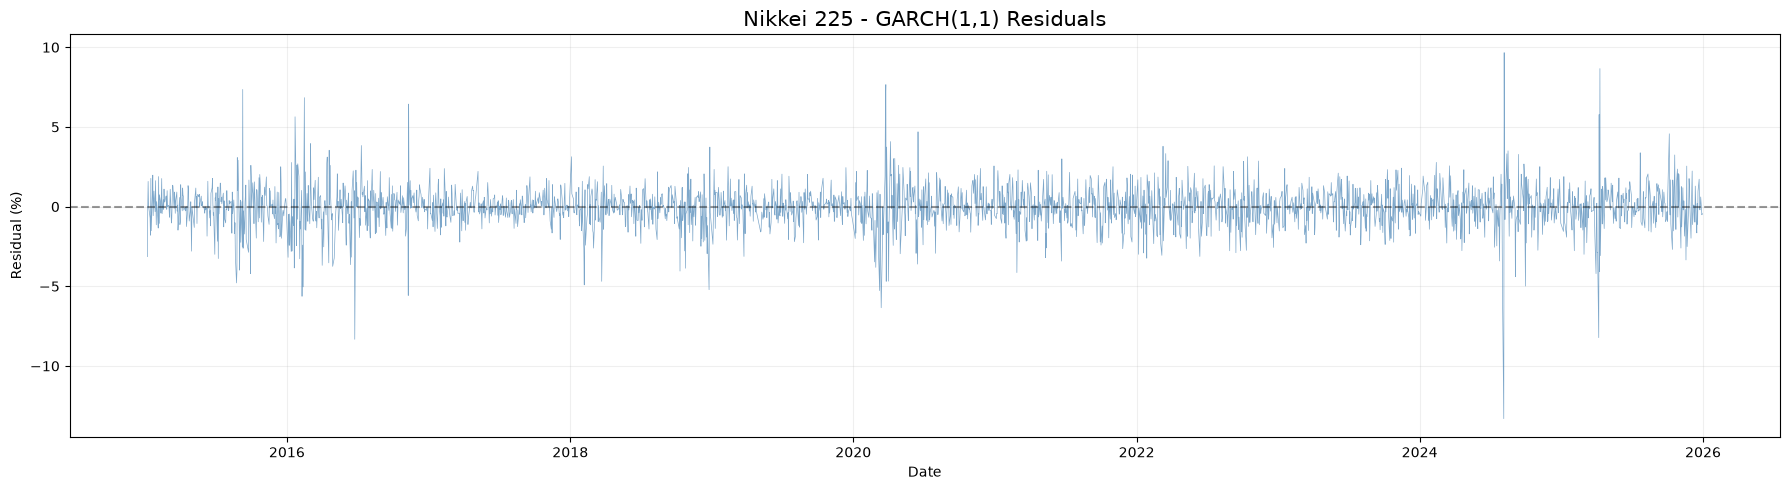

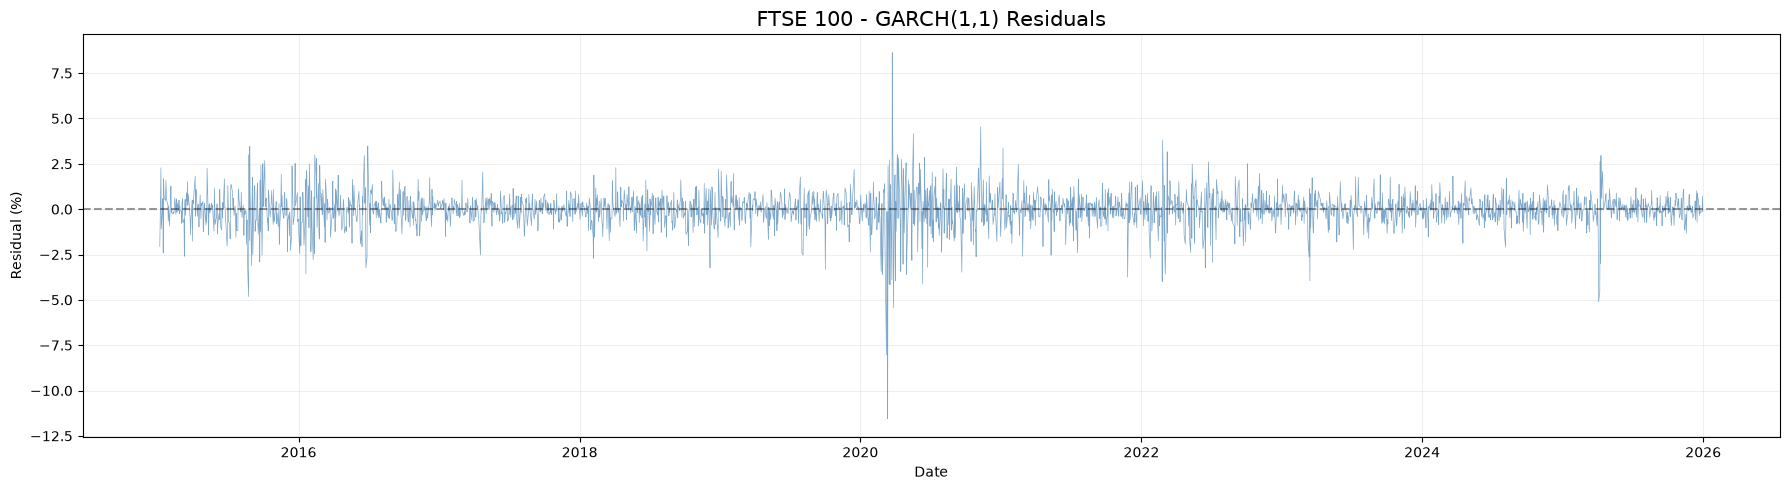

In [460]:
# Plot GARCH residuals for each equity index

for name, residuals in garch_residuals.items():

    plt.figure(figsize=(18, 5))

    plt.plot(
        residuals.index,
        residuals,
        linewidth=0.5,
        alpha=0.7,
        color="steelblue"
    )

    plt.title(
        f"{name} - GARCH(1,1) Residuals",
        fontsize=15
    )

    plt.xlabel("Date")
    plt.ylabel("Residual (%)")

    plt.axhline(
        0,
        color="black",
        linestyle="--",
        alpha=0.4
    )

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### Conditional Volatility Plots

We visualise the estimated conditional volatility from the fitted GARCH(1,1) models for the four equity indices.

The conditional volatility is defined as:

$$\sigma_t = \sqrt{\sigma_t^2}$$

Unlike rolling volatility, which is calculated using a fixed historical window, GARCH conditional volatility is estimated dynamically using past shocks and conditional variances.

These plots allow us to examine time-varying market volatility, identify periods of heightened uncertainty, and compare volatility dynamics across global equity markets.

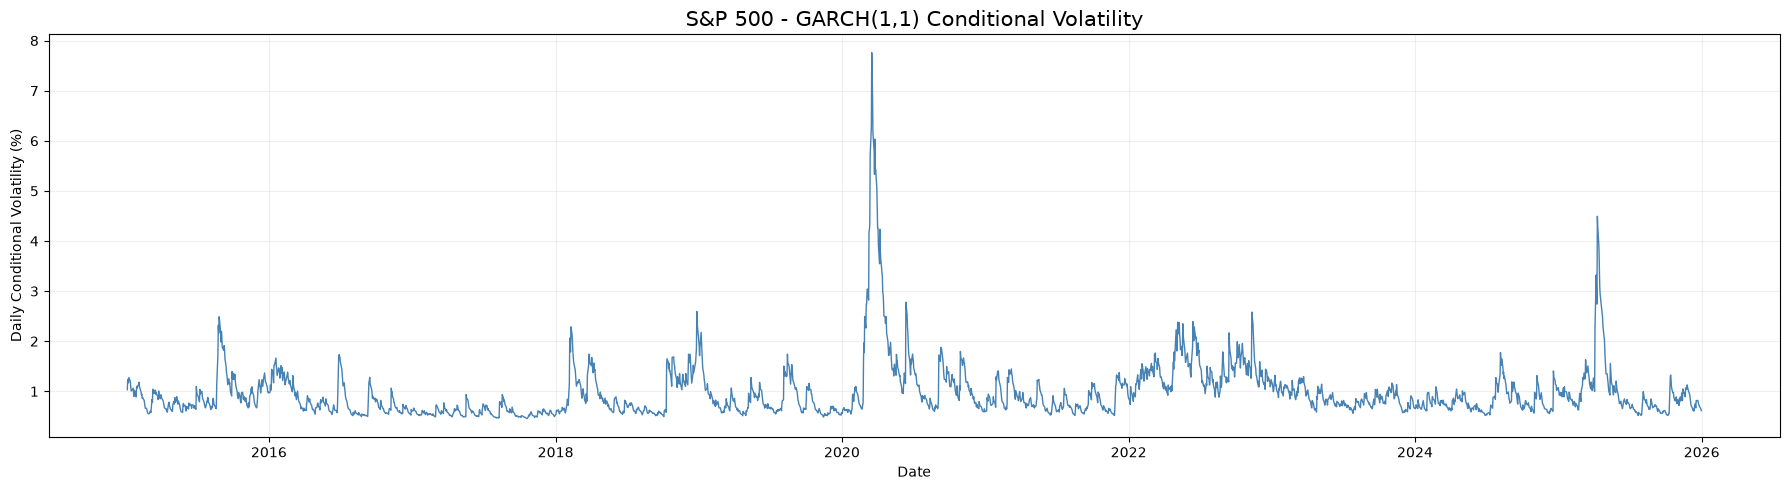

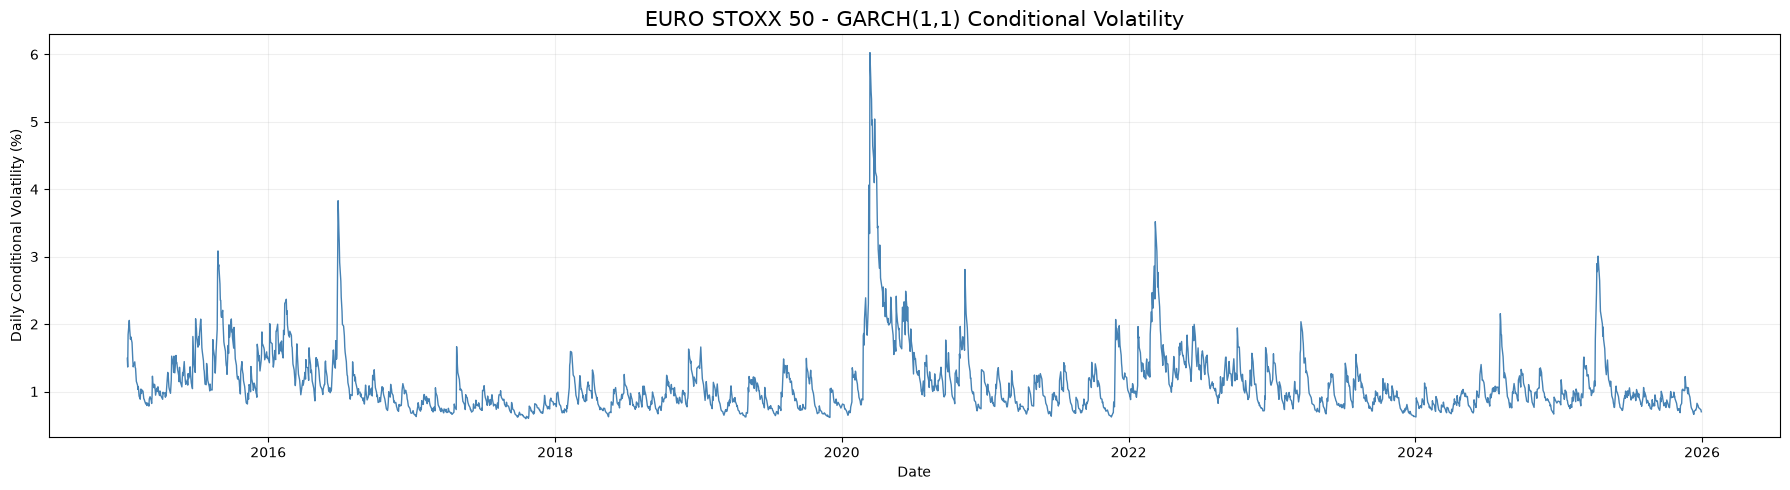

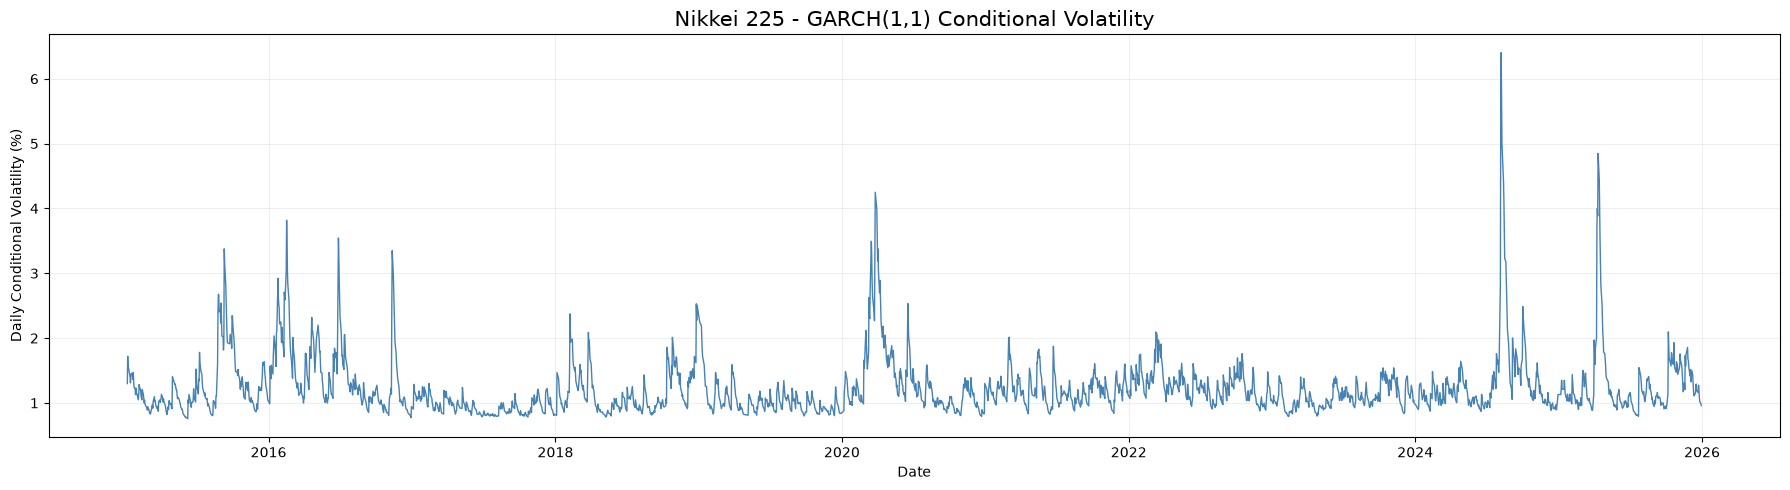

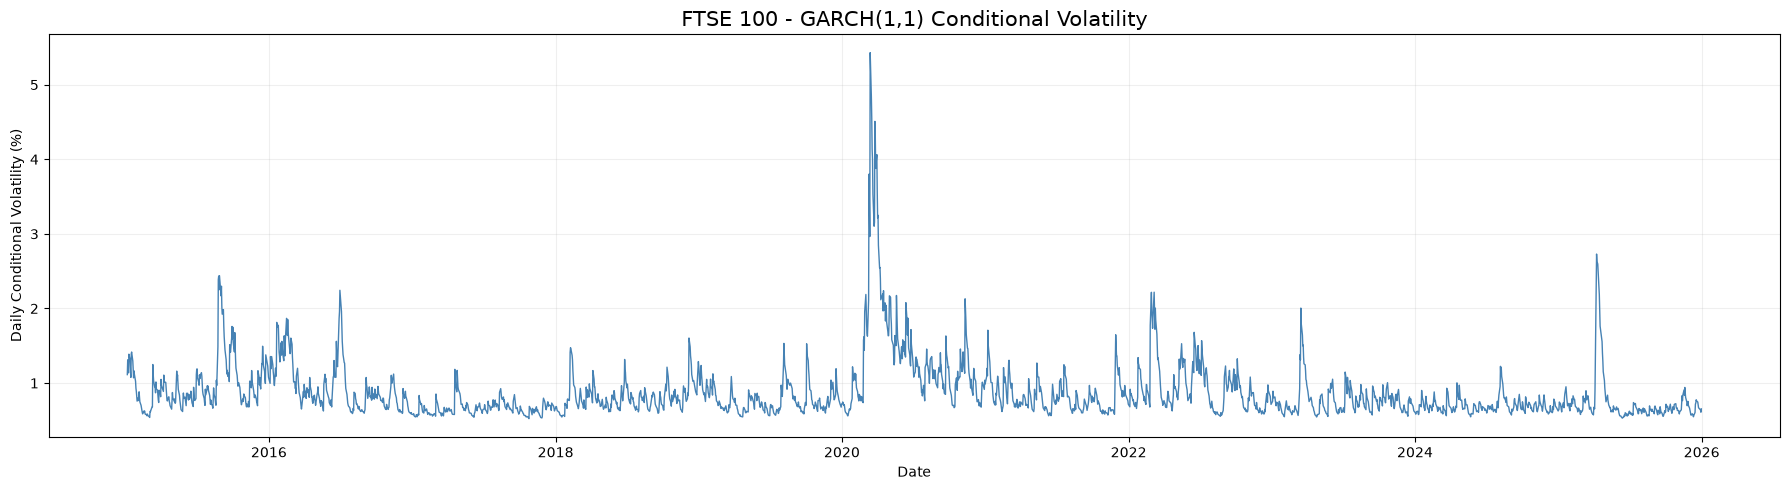

In [461]:

# Plot GARCH(1,1) conditional volatility

for name, result in garch_results.items():

    conditional_vol = result.conditional_volatility

    plt.figure(figsize=(18, 5))

    plt.plot(
        conditional_vol.index,
        conditional_vol,
        linewidth=1,
        color="steelblue"
    )

    plt.title(
        f"{name} - GARCH(1,1) Conditional Volatility",
        fontsize=15
    )

    plt.xlabel("Date")
    plt.ylabel("Daily Conditional Volatility (%)")

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


### Standardised Residual Diagnostics

Standardised residuals are calculated by
dividing the model residuals by the
estimated conditional volatility:

$$\hat{z}_t =
\frac{\hat{\epsilon}_t}{\hat{\sigma}_t}$$

Standardisation accounts for changes in
conditional volatility over time, allowing
shocks to be compared on a common scale.

We examine the standardised residual series
to assess whether the fitted GARCH(1,1)
models adequately capture volatility
clustering.

Ideally, the standardised residuals should
show no obvious remaining volatility patterns.

In [462]:
# Extract standardised residuals

garch_std_residuals = {}

for name, result in garch_results.items():

    garch_std_residuals[name] = result.std_resid.dropna()

    print(
        f"{name}: {len(garch_std_residuals[name])} observations"
    )

S&P 500: 2765 observations
EURO STOXX 50: 2762 observations
Nikkei 225: 2687 observations
FTSE 100: 2777 observations


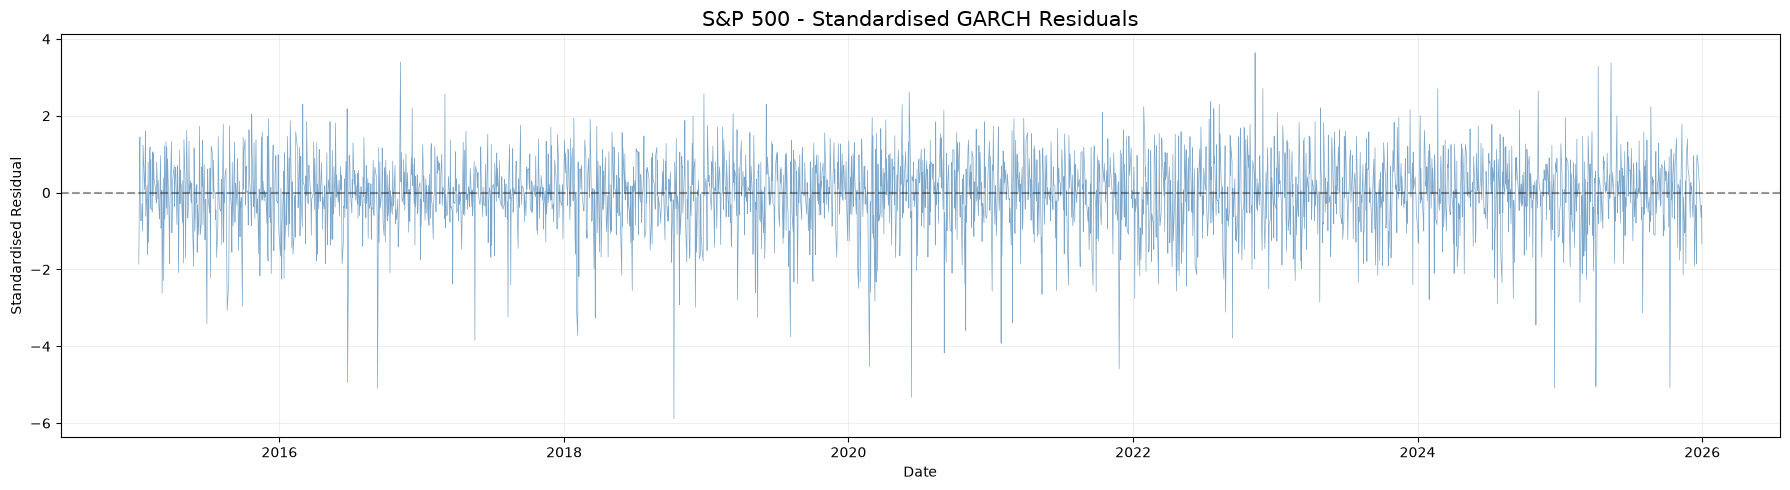

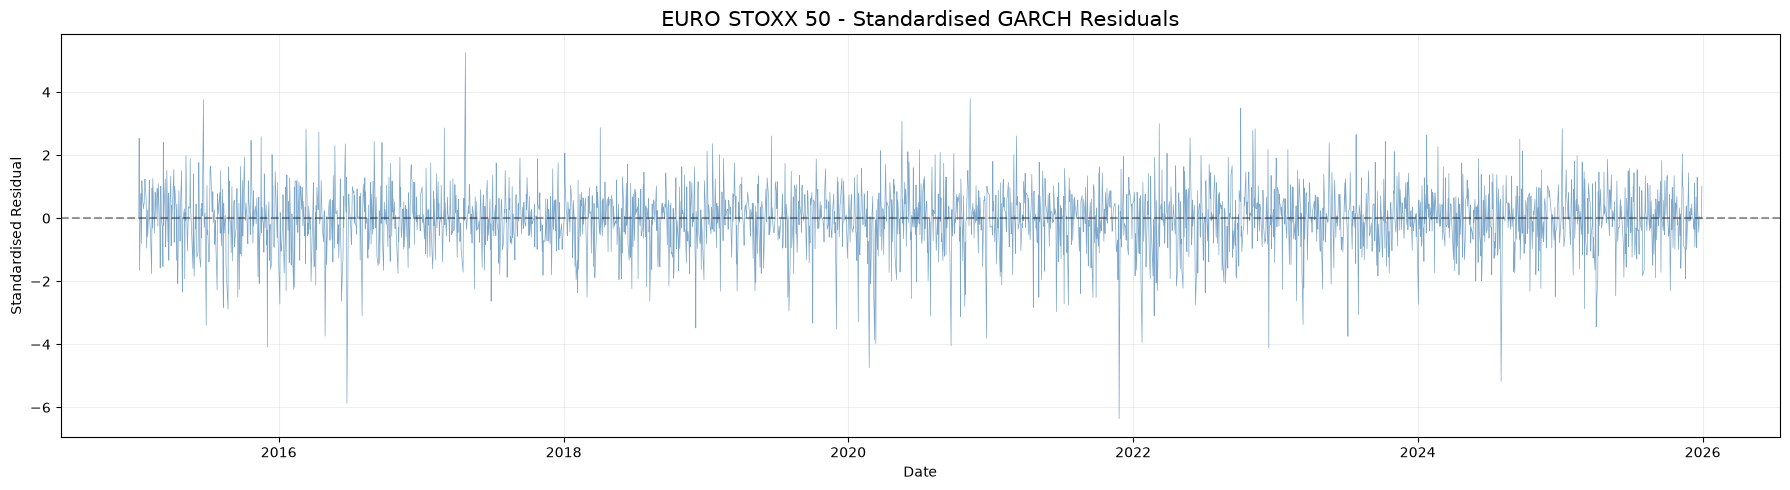

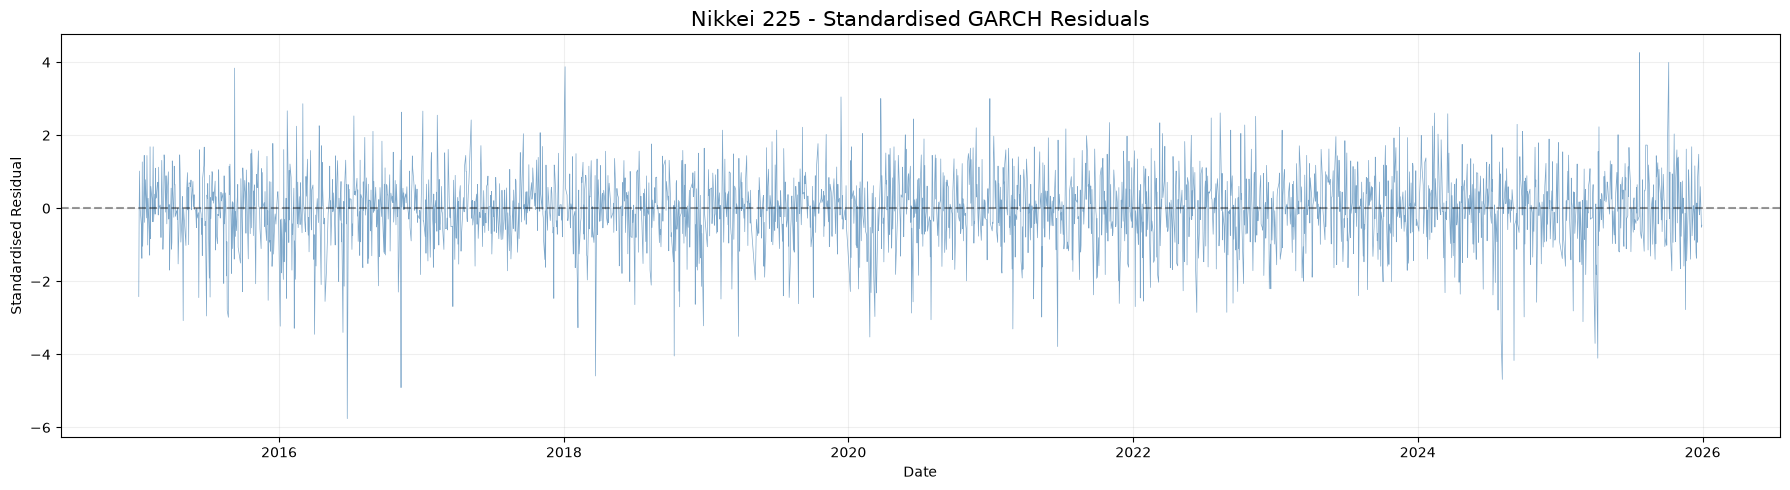

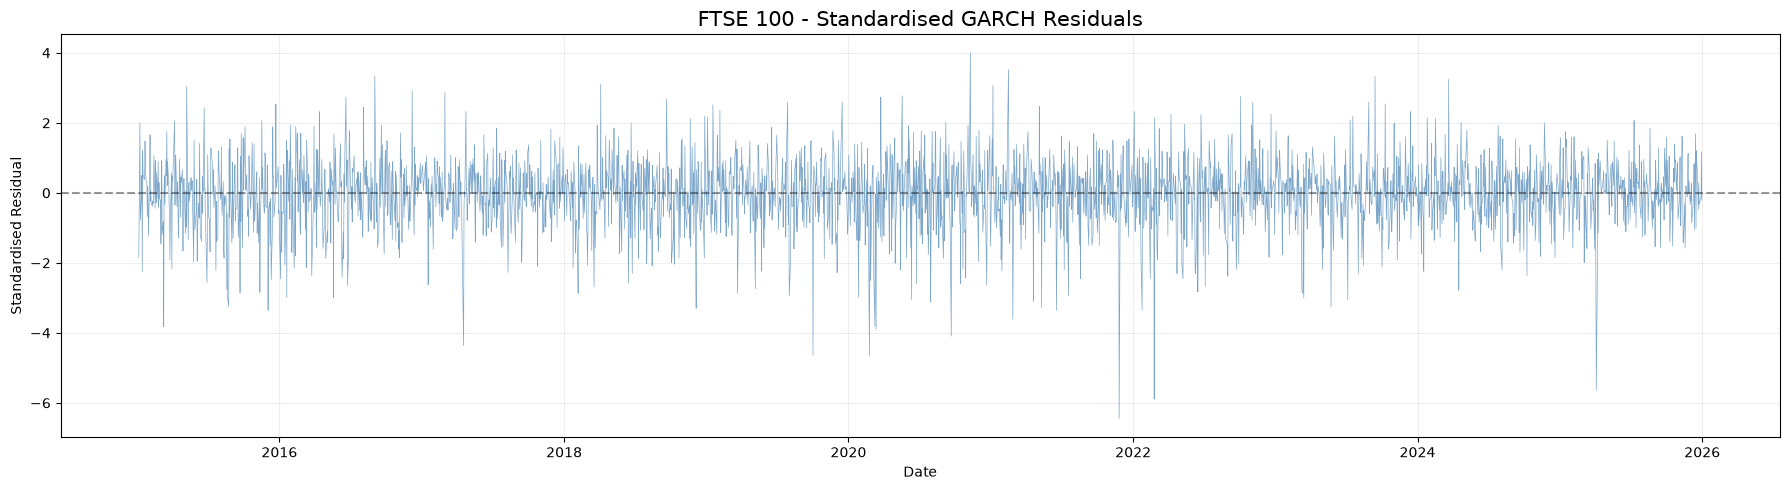

In [463]:
# Plot standardised GARCH residuals

for name, std_resid in garch_std_residuals.items():

    plt.figure(figsize=(18, 5))

    plt.plot(
        std_resid.index,
        std_resid,
        linewidth=0.5,
        alpha=0.7,
        color="steelblue"
    )

    plt.title(
        f"{name} - Standardised GARCH Residuals",
        fontsize=15
    )

    plt.xlabel("Date")
    plt.ylabel("Standardised Residual")

    plt.axhline(
        0,
        color="black",
        linestyle="--",
        alpha=0.4
    )

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### AIC and BIC

The Akaike Information Criterion (AIC) and
Bayesian Information Criterion (BIC) are
reported to assess model fit while accounting
for model complexity.

The criteria are defined as:

$$AIC = 2k - 2\ln(\hat{L})$$

$$BIC = k\ln(n) - 2\ln(\hat{L})$$

where $k$ is the number of estimated parameters,
$n$ is the sample size, and $\hat{L}$ is the
maximised likelihood.

Lower values are generally preferred when
comparing candidate models fitted to the same
return series.

Since the four indices have different
observations and return distributions,
their AIC and BIC values are reported
descriptively rather than used to rank
model quality across markets.

In [464]:
# Extract AIC and BIC from fitted GARCH models

model_evaluation = []

for name, result in garch_results.items():

    model_evaluation.append({
        "Index": name,
        "AIC": result.aic,
        "BIC": result.bic
    })

aic_bic_table = pd.DataFrame(model_evaluation)

display(aic_bic_table.round(2))

,Index,AIC,BIC
0,S&P 500,7152.24,7175.94
1,EURO STOXX 50,8045.52,8069.22
2,Nikkei 225,8500.28,8523.86
3,FTSE 100,6793.17,6816.89


### Volatility Forecasting

One-step-ahead conditional volatility forecasts
are generated using the fitted GARCH(1,1)
models for the four equity indices.

The forecast conditional variance is given by:

$$\hat{\sigma}_{t+1|t}^{2}
=\hat{\omega}
+\hat{\alpha}\hat{\epsilon}_{t}^{2}
+\hat{\beta}\hat{\sigma}_{t}^{2}$$

The conditional volatility forecast is obtained
by taking the square root of the forecast
variance:

$$\hat{\sigma}_{t+1|t}
=\sqrt{\hat{\sigma}_{t+1|t}^{2}}$$

These forecasts provide model-based estimates
of next-period return volatility, rather than
predictions of the direction of market returns.

In [465]:
# One-step-ahead volatility forecasts for all indices

volatility_forecasts = []

for name, result in garch_results.items():

    forecast = result.forecast(horizon=1)

    variance = forecast.variance.iloc[-1, 0]

    volatility = np.sqrt(variance)

    volatility_forecasts.append({
        "Index": name,
        "Forecast Variance": variance,
        "Forecast Volatility (%)": volatility
    })

forecast_table = pd.DataFrame(volatility_forecasts)

display(forecast_table.round(4))

,Index,Forecast Variance,Forecast Volatility (%)
0,S&P 500,0.4571,0.6761
1,EURO STOXX 50,0.5335,0.7304
2,Nikkei 225,0.8627,0.9288
3,FTSE 100,0.3876,0.6226


## 9. Results and Interpretation
### GARCH Parameter Estimates and Volatility Persistence

The estimated GARCH(1,1) parameters, volatility persistence coefficients, information criteria, and one-step-ahead volatility forecasts are summarised for the four equity indices.

The results are used to compare volatility persistence and conditional volatility dynamics across markets. Model diagnostics and information criteria are interpreted separately to assess the fitted models.

In [466]:
# Combine GARCH estimation and evaluation results

summary_table = (
    parameter_table
    .merge(aic_bic_table, on="Index")
    .merge(forecast_table, on="Index")
)

display(summary_table.round(4))

,Index,Mu,Omega,Alpha,Beta,Persistence,Convergence Flag,AIC,BIC,Forecast Variance,Forecast Volatility (%)
0,S&P 500,0.0789,0.0395,0.1748,0.7938,0.9685,0,7152.2406,7175.9397,0.4571,0.6761
1,EURO STOXX 50,0.0628,0.0625,0.1540,0.8046,0.9586,0,8045.5217,8069.2165,0.5335,0.7304
2,Nikkei 225,0.0737,0.1198,0.1562,0.7733,0.9294,0,8500.2768,8523.8615,0.8627,0.9288
3,FTSE 100,0.0372,0.0599,0.1706,0.7589,0.9296,0,6793.1696,6816.8861,0.3876,0.6226


### Interpretation of GARCH Results

**Volatility Persistence**

The estimated GARCH(1,1) models reveal differences in volatility persistence across the four global equity indices.

The S&P 500 exhibits the highest estimated persistence coefficient (0.9685), followed by the EURO STOXX 50 (0.9586). The FTSE 100 (0.9296) and Nikkei 225 (0.9294) show lower and nearly identical persistence.

These findings suggest that volatility shocks tend to decay more slowly in the S&P 500 under the fitted model. However, the statistical significance of the differences has not been established.

**Residual Diagnostics**

Original and standardised residual plots were generated for each market to examine the behaviour of the fitted models.

Standardising residuals by their estimated conditional volatility allows shocks occurring during different volatility regimes to be compared on a common scale. Visual inspection provides preliminary diagnostic evidence but does not establish that all remaining volatility dependence has been removed.

**AIC and BIC**

AIC and BIC were calculated for all four GARCH(1,1) models. These criteria summarise model fit while penalising model complexity.

Since the models were estimated using different market return series, their absolute AIC and BIC values are reported descriptively rather than used to rank model quality across markets.

**Volatility Forecasts**

The one-step-ahead volatility forecasts differ across the four indices.

The Nikkei 225 has the highest forecast daily volatility (0.9288%), followed by the EURO STOXX 50 (0.7304%), S&P 500 (0.6761%), and FTSE 100 (0.6226%).

Notably, the S&P 500 exhibits the highest volatility persistence, whereas the Nikkei 225 has the highest forecast volatility. This highlights the distinction between the persistence of volatility shocks and the expected magnitude of next-period return fluctuations.

**Overall Interpretation**

The results indicate differences in estimated volatility dynamics across global equity markets. The GARCH(1,1) framework provides a consistent approach for analysing volatility persistence and generating conditional volatility forecasts.

However, the results depend on the selected sample period, model specification, and distributional assumptions.